In [1]:
# Import the libraries
import kagglehub
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
import importlib
import utils
importlib.reload(utils)
from utils import brand_variant_rules, normalize_variant, extract_variant, get_state_name, get_final_dataset

### Dataset-1

In [2]:
# Import the first dataset from kaggle
path = kagglehub.dataset_download(handle="mrmars1010/cars-india-pre-owned", 
                                  output_dir=r".\Raw Datasets\CarsIndia")
df1 = pd.read_csv(os.path.join(path, "pre-owned cars.csv"))
df1.head()

,brand,model,transmission,make_year,reg_year,fuel_type,engine_capacity(CC),km_driven,ownership,price,overall_cost,has_insurance,spare_key,reg_number,title
0,Mahindra,Thar LX D 4WD MT CONVERTIBLE,Manual,2020.0,01-01-2021,Diesel,2184.0,11003.0,1st owner,1231000,23431.0,True,No,HR26,2020 Mahindra Thar LX D 4WD MT CONVERTIBLE
1,Hyundai,Verna 1.6 VTVT SX,Manual,2018.0,01-07-2018,Petrol,1591.0,66936.0,1st owner,786000,15359.0,True,No,DL7C,2018 Hyundai Verna 1.6 VTVT SX
2,Tata,Harrier XT PLUS 2.0L KRYOTEC DARK EDITON,Manual,2022.0,01-08-2022,Diesel,1956.0,27990.0,1st owner,1489000,28349.0,True,No,HR29,2022 Tata Harrier XT PLUS 2.0L KRYOTEC DARK ED...
3,Honda,City 1.5L I-VTE V CVT,Automatic,2023.0,01-04-2023,Petrol,1498.0,5061.0,1st owner,1227000,23355.0,True,Yes,DL4C,2023 Honda City 1.5L I-VTE V CVT
4,Ford,Ecosport TITANIUM 1.5L DIESEL,Manual,2021.0,01-07-2021,Diesel,1498.0,23480.0,1st owner,887000,16883.0,True,No,UP14,2021 Ford Ecosport TITANIUM 1.5L DIESEL


In [3]:
# Drop the last row which has the sum of prices
df1.drop(index=[2805], axis=0, inplace=True)

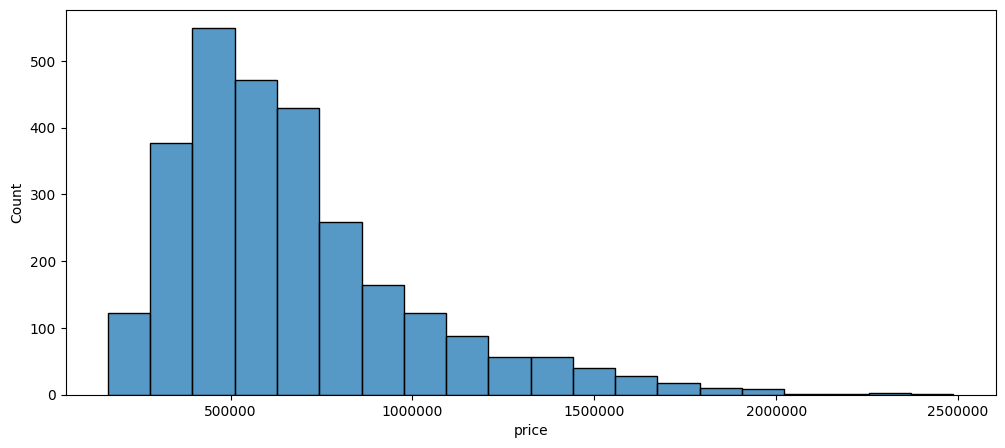

In [4]:
# Visualize the target feature (price)
plt.figure(figsize=(12, 5))
sns.histplot(data=df1, x='price', bins=20)
plt.ticklabel_format(style='plain', axis='x')
plt.show()

The maximum of the used cars are sold at a price range of Rs 3-8 lacs. A few of the cars are sold for above Rs 20 lacs which needs further investigation.

In [5]:
# Investigate the outliers in target feature
df1[df1['price']>=2000000]

,brand,model,transmission,make_year,reg_year,fuel_type,engine_capacity(CC),km_driven,ownership,price,overall_cost,has_insurance,spare_key,reg_number,title
8,Mahindra,XUV700 AX 7 LUXURY D AWD AT 7 STR,Automatic,2022.0,01-04-2022,Diesel,2184.0,62567.0,1st owner,2322000,44197.0,True,No,DL10,2022 Mahindra XUV700 AX 7 LUXURY D AWD AT 7 STR
696,MG,HECTOR SAVVY PRO 1.5 TURBO CVT PETROL,Automatic,2023.0,01-02-2023,Petrol,1451.0,30857.0,1st owner,2004000,38144.0,True,No,UP16,2023 MG HECTOR SAVVY PRO 1.5 TURBO CVT PETROL
708,Toyota,Innova Crysta 2.7 VX 7 STR,Manual,2022.0,01-01-2023,Petrol,2694.0,21296.0,1st owner,2051000,39039.0,True,No,UP16,2022 Toyota Innova Crysta 2.7 VX 7 STR
729,Mahindra,XUV700 AX 7 LUXURY P AT 7 STR,Automatic,2023.0,NaN,Petrol,1997.0,11330.0,1st owner,2487000,47338.0,True,No,KA01,2023 Mahindra XUV700 AX 7 LUXURY P AT 7 STR
963,Tata,Safari XZA PLUS DARK EDITION,Automatic,2022.0,NaN,Diesel,1956.0,15681.0,1st owner,2173000,41359.0,True,No,KA51,2022 Tata Safari XZA PLUS DARK EDITION
1103,MG,HECTOR PLUS SELECT 2.0 DIESEL TURBO MT 7-STR,Manual,2022.0,NaN,Diesel,1956.0,15431.0,1st owner,2016000,38373.0,True,No,KA05,2022 MG HECTOR PLUS SELECT 2.0 DIESEL TURBO MT...
1486,Mahindra,XUV700 AX 7 P MT 7 STR,Manual,2022.0,NaN,Petrol,1997.0,16062.0,1st owner,2005000,38163.0,True,Yes,KA02,2022 Mahindra XUV700 AX 7 P MT 7 STR
2060,Mahindra,XUV700 AX 7 LUXURY D AT 7 STR,Automatic,2022.0,NaN,Diesel,2184.0,42398.0,1st owner,2261000,43036.0,True,No,TS07,2022 Mahindra XUV700 AX 7 LUXURY D AT 7 STR
2145,Mahindra,XUV700 AX 5 P AT 5 STR,Automatic,2022.0,NaN,Petrol,1997.0,31604.0,1st owner,2007000,38201.0,True,Yes,TS07,2022 Mahindra XUV700 AX 5 P AT 5 STR


From the above data, we could could see that those are comparatively newer cars and with more features than others. So, these data doesn't seems to be erronous. These data can be kept.

In [6]:
# Change the car brand Maruti to Maruti Suzuki in order to match with other data frames
df1['brand'] = df1['brand'].replace('Maruti', 'Maruti Suzuki')
df1['brand'].unique()

<ArrowStringArray>
[     'Mahindra',       'Hyundai',          'Tata',         'Honda',
          'Ford', 'Maruti Suzuki',           'KIA',            'MG',
       'Renault',    'Volkswagen',        'Nissan',         'Skoda',
        'Toyota',        'Datsun',          'Jeep']
Length: 15, dtype: str

In [7]:
# Apply the varient extraction function to the dataframe
df1['variant'] = df1.apply(lambda row: extract_variant(row['model'], row['brand']), axis=1)
df1.head(1)

,brand,model,transmission,make_year,reg_year,fuel_type,engine_capacity(CC),km_driven,ownership,price,overall_cost,has_insurance,spare_key,reg_number,title,variant
0,Mahindra,Thar LX D 4WD MT CONVERTIBLE,Manual,2020.0,01-01-2021,Diesel,2184.0,11003.0,1st owner,1231000,23431.0,True,No,HR26,2020 Mahindra Thar LX D 4WD MT CONVERTIBLE,LX


In [8]:
# Standardize the names by converting to upper case
for col in ['brand', 'model', 'variant']:
    df1[col] = df1[col].str.upper()
df1.head(1)

,brand,model,transmission,make_year,reg_year,fuel_type,engine_capacity(CC),km_driven,ownership,price,overall_cost,has_insurance,spare_key,reg_number,title,variant
0,MAHINDRA,THAR LX D 4WD MT CONVERTIBLE,Manual,2020.0,01-01-2021,Diesel,2184.0,11003.0,1st owner,1231000,23431.0,True,No,HR26,2020 Mahindra Thar LX D 4WD MT CONVERTIBLE,LX


In [9]:
# Check for unique brand names
print(sorted(df1['brand'].unique()))

['DATSUN', 'FORD', 'HONDA', 'HYUNDAI', 'JEEP', 'KIA', 'MAHINDRA', 'MARUTI SUZUKI', 'MG', 'NISSAN', 'RENAULT', 'SKODA', 'TATA', 'TOYOTA', 'VOLKSWAGEN']


In [10]:
# Create a function to remove the unwanted text from the model field
def remove_variant_and_after(title, variant):
    pattern = re.escape(str(variant))
    return re.split(pattern, title, flags=re.IGNORECASE)[0].strip()

In [11]:
# Extract the name of model by removing the varient and other details
df1['model'] = df1.apply(lambda x: remove_variant_and_after(x['model'], x['variant']), axis=1)
df1.head(1)

,brand,model,transmission,make_year,reg_year,fuel_type,engine_capacity(CC),km_driven,ownership,price,overall_cost,has_insurance,spare_key,reg_number,title,variant
0,MAHINDRA,THAR,Manual,2020.0,01-01-2021,Diesel,2184.0,11003.0,1st owner,1231000,23431.0,True,No,HR26,2020 Mahindra Thar LX D 4WD MT CONVERTIBLE,LX


In [12]:
# Check for the unique model names
print(sorted(df1['model'].unique()))

['', 'A STAR', 'ALCAZAR 2.0', 'ALTO', 'ALTO 800', 'ALTO K10', 'ALTROZ', 'AMAZ', 'AMAZE 1.2L I-', 'AMAZE 1.2L I-VTEC', 'AMAZE 1.5L I-DTEC', 'AMEO', 'AMEO HIGHLINE1.2L', 'AMEO HIGHLINE1.5L', 'AURA', 'BALENO', 'BOLERO', 'BR-', 'BR-V 1.5L I-VTEC', 'BREZZA', 'BRIO', 'CARENS', 'CELERIO', 'CELERIO X', 'CI', 'CIAZ', 'CITY 1.5L I-', 'CITY 1.5L I-DTEC', 'CITY 1.5L I-VTE', 'CITY 1.5L I-VTEC', 'CIVIC 1.8L I-VTEC', 'COMPASS', 'COROLLA ALTIS', 'CR', 'CRETA', 'DUSTER', 'DUSTER 110 PS', 'DUSTER 85 PS', 'DZIRE', 'ECOSPORT', 'EECO 5 STR', 'EECO 5 STR AC CNG', 'EECO 7 STR', 'ELITE I20', 'EON', 'ERTIGA', 'ETIOS', 'ETIOS CROSS 1.4', 'ETIOS LIVA', 'FREESTYLE', 'GLANZA', 'GO', 'GO PLUS', 'GRAND I10', 'GRAND I10 NIOS', 'GRAND VITARA', 'HARRIER', 'HECTOR', 'HECTOR PLUS', 'I10', 'I20', 'I20 ACTIVE 1.2', 'I20 ACTIVE 1.4', 'IGNIS', 'INNOVA CRYSTA 2.7', 'JAZZ 1.2L I-', 'JAZZ 1.2L I-VTEC', 'KIGER', 'KUSHAQ', 'KUV 100 NXT', 'KUV100', 'KWID', 'KWID 1.0 MARVEL', 'KWID NEOTECH', 'MAGNITE', 'MICRA', 'MICRA ACTIVE', 'NAN

We could see that there are some models where the engine specifications or any other word appear after the model name. So, we need to identifiy those and remove the trailing words after that.

In [13]:
# Check for unique model names having more than one word using list comprehension
multi_word_models = [model for model in df1['model'].unique() if len(str(model).split(' '))>1]
print(sorted(multi_word_models))

['A STAR', 'ALCAZAR 2.0', 'ALTO 800', 'ALTO K10', 'AMAZE 1.2L I-', 'AMAZE 1.2L I-VTEC', 'AMAZE 1.5L I-DTEC', 'AMEO HIGHLINE1.2L', 'AMEO HIGHLINE1.5L', 'BR-V 1.5L I-VTEC', 'CELERIO X', 'CITY 1.5L I-', 'CITY 1.5L I-DTEC', 'CITY 1.5L I-VTE', 'CITY 1.5L I-VTEC', 'CIVIC 1.8L I-VTEC', 'COROLLA ALTIS', 'DUSTER 110 PS', 'DUSTER 85 PS', 'EECO 5 STR', 'EECO 5 STR AC CNG', 'EECO 7 STR', 'ELITE I20', 'ETIOS CROSS 1.4', 'ETIOS LIVA', 'GO PLUS', 'GRAND I10', 'GRAND I10 NIOS', 'GRAND VITARA', 'HECTOR PLUS', 'I20 ACTIVE 1.2', 'I20 ACTIVE 1.4', 'INNOVA CRYSTA 2.7', 'JAZZ 1.2L I-', 'JAZZ 1.2L I-VTEC', 'KUV 100 NXT', 'KWID 1.0 MARVEL', 'KWID NEOTECH', 'MICRA ACTIVE', 'NANO TWIST', 'NEW ELANTRA 1.6', 'NEW I20', 'NEW I20 N LINE', 'NEW SANTRO', 'NEW WAGON-R', 'NEXON EV', 'POLO HIGHLINE1.2L', 'POLO HIGHLINE1.5L', 'RAPID 1.6 MPI', 'REDI GO', 'S CROSS', 'S PRESSO', 'SANTRO XING', 'SWIFT DZIRE', 'TIAGO EV', 'URBAN CRUISER', 'VERNA 1.6', 'VERNA 1.6 CRDI', 'VERNA 1.6 VTVT', 'VERNA FLUIDIC 1.6 CRDI', 'VERNA FLUIDI

We could see there are some model names along with their engine type or capacity attached to it. We need to remove those suffixes and keep the model name only. Some of these are:
1. CITY  I-VTEC
2. EECO 5 STR AC CNG
3. SELTOS X LINE  DCT

Also there are some models like 'NEW I20 N LINE' where new prefix is added before the model name. However, the model is same as before. So, we will remove the prefix here.

In [14]:
# For some of the models, extract the first word only
models = ['ALCAZAR', 'AMAZE', 'AMEO', 'BR-V', 'CARENS', 'CITY', 'CIVIC', 'DUSTER', 'EECO', 'JAZZ', 'KWID', 
          'MICRA', 'POLO', 'RAPID', 'SELTOS', 'SONET', 'VERNA', 'WR-V']
mask = df1['model'].str.upper().str.contains('|'.join(models), na=False)
df1.loc[mask, 'model'] = df1.loc[mask, 'model'].str.split().str[0]

In [15]:
# For some of the models, extract the first and second word only
models = ['ETIOS CROSS', 'INNOVA CRYSTA', 'KUV 100', 'WAGON R', 'I20']
mask = df1['model'].str.upper().str.contains('|'.join(map(re.escape, models)), na=False)
df1.loc[mask, 'model'] = (df1.loc[mask, 'model'].str.split().str[:2].str.join(' '))

In [16]:
# Replace the other models starting with new
new_models = [model for model in df1['model'].unique() if str(model).split(' ')[0]=='NEW']
print(sorted(new_models))

['NEW ELANTRA 1.6', 'NEW I20', 'NEW SANTRO', 'NEW WAGON-R']


In [17]:
# Remove the new word from the models
mask = df1['model'].str.upper().str.contains('|'.join(new_models), na=False)
df1.loc[mask, 'model'] = df1.loc[mask, 'model'].str.replace(r'^NEW\s+', '', regex=True)

In [18]:
# Replace the wrong model names with their correct names 
wrong_model_mapping = {'CI': 'CITY', 'CR': 'CRETA', 'V': 'VENUE', 'XC': 'XCENT', 'WR-': 'WR-V', 'BR-': 'BR-V', 
                       'AMAZ': 'AMAZE'}
df1['model'] = df1['model'].replace(wrong_model_mapping)

In [19]:
# Check for blank model name
df1[df1['model']=='']

,brand,model,transmission,make_year,reg_year,fuel_type,engine_capacity(CC),km_driven,ownership,price,overall_cost,has_insurance,spare_key,reg_number,title,variant
183,TOYOTA,,Automatic,2019.0,01-01-2020,Petrol,1197.0,55311.0,2nd owner,622000,12160.0,True,No,HR26,2019 Toyota Glanza G CVT,G
892,TOYOTA,,Automatic,2021.0,NaN,Petrol,1197.0,28290.0,2nd owner,774000,15131.0,True,Yes,KA04,2021 Toyota Glanza G CVT,G
955,TOYOTA,,Manual,2019.0,NaN,Petrol,1197.0,45958.0,1st owner,686000,13414.0,True,No,KA03,2019 Toyota Glanza G ISG,G
1394,TOYOTA,,Automatic,2021.0,NaN,Petrol,1197.0,16893.0,1st owner,810000,15417.0,True,No,KA01,2021 Toyota Glanza G CVT,G
1403,TOYOTA,,Manual,2021.0,NaN,Petrol,1197.0,25206.0,1st owner,793000,15497.0,True,No,KA04,2021 Toyota Glanza G,G
1682,TOYOTA,,Manual,2020.0,NaN,Petrol,1197.0,68494.0,2nd owner,633000,12368.0,True,No,KA04,2020 Toyota Glanza G,G
2062,TOYOTA,,Automatic,2022.0,NaN,Petrol,1197.0,18863.0,1st owner,846000,16103.0,True,No,TS07,2022 Toyota Glanza G AMT,G


In [20]:
# replace the blank model with Glanza
df1['model'] = df1['model'].replace('', 'GLANZA')

In [21]:
# Check for unique models
print(sorted(df1['model'].unique()))

['A STAR', 'ALCAZAR', 'ALTO', 'ALTO 800', 'ALTO K10', 'ALTROZ', 'AMAZE', 'AMEO', 'AURA', 'BALENO', 'BOLERO', 'BR-V', 'BREZZA', 'BRIO', 'CARENS', 'CELERIO', 'CELERIO X', 'CIAZ', 'CITY', 'CIVIC', 'COMPASS', 'COROLLA ALTIS', 'CRETA', 'DUSTER', 'DZIRE', 'ECOSPORT', 'EECO', 'ELANTRA 1.6', 'ELITE I20', 'EON', 'ERTIGA', 'ETIOS', 'ETIOS CROSS', 'ETIOS LIVA', 'FREESTYLE', 'GLANZA', 'GO', 'GO PLUS', 'GRAND I10', 'GRAND I10 NIOS', 'GRAND VITARA', 'HARRIER', 'HECTOR', 'HECTOR PLUS', 'I10', 'I20', 'I20 ACTIVE', 'IGNIS', 'INNOVA CRYSTA', 'JAZZ', 'KIGER', 'KUSHAQ', 'KUV 100', 'KUV100', 'KWID', 'MAGNITE', 'MICRA', 'NANO TWIST', 'NEXON', 'NEXON EV', 'OMNI', 'POLO', 'PULSE', 'PUNCH', 'RAPID', 'REDI GO', 'RITZ', 'S CROSS', 'S PRESSO', 'SAFARI', 'SANTRO', 'SANTRO XING', 'SCORPIO', 'SELTOS', 'SLAVIA', 'SONET', 'SWIFT', 'SWIFT DZIRE', 'TAIGUN', 'TERRANO', 'THAR', 'TIAGO', 'TIAGO EV', 'TIGOR', 'TRIBER', 'TUCSON', 'TUV300', 'URBAN CRUISER', 'VENTO', 'VENUE', 'VERNA', 'VIRTUS', 'VITARA BREZZA', 'WAGON R', 'WAG

In [22]:
# Check for unique variants
df1['variant'] = df1['variant'].astype('str')
print(df1['variant'].unique())

<ArrowStringArray>
[             'LX',              'SX',         'XT PLUS',           'V CVT',
        'TITANIUM',              'VX',        'CREATIVE',             'XMA',
            'AX 7',      'TITANIUM +',
 ...
          'AC (O)', 'XM PLUS SUNROOF',     'RXT 0.8 (O)',              'VL',
    'ACCOMPLISHED',          'ACTIVE',              'S+',   'SX AT 1.2 (O)',
            'HIGH',      'FEARLESS +']
Length: 198, dtype: str


In [23]:
# Apply the normalization function to the model and variant
df1['model'] = df1['model'].apply(normalize_variant)
df1['variant'] = df1['variant'].apply(normalize_variant)

In [24]:
# Change the datatype of model and variant to string
df1['model'] = df1['model'].astype(str)
df1['variant'] = df1['variant'].astype(str)

In [25]:
# Check for unique model and variant after normalization
print('Unique Model\n', df1['model'].unique())
print('Unique Variant\n', df1['variant'].unique())

Unique Model
 <ArrowStringArray>
[         'THAR',         'VERNA',       'HARRIER',          'CITY',
      'ECOSPORT',          'WR-V',         'PUNCH',         'NEXON',
        'XUV700',         'DZIRE',
 ...
          'ZEST',       'TERRANO',    'NANO TWIST',       'ALCAZAR',
  'GRAND VITARA',         'CIVIC',            'GO',        'SLAVIA',
       'ELANTRA', 'COROLLA ALTIS']
Length: 103, dtype: str
Unique Variant
 <ArrowStringArray>
[          'LX',           'SX',          'XT+',        'V CVT',
     'TITANIUM',           'VX',     'CREATIVE',          'XMA',
         'AX 7',    'TITANIUM+',
 ...
       'STD(O)',        'AC(O)',  'XM+ SUNROOF',           'VL',
 'ACCOMPLISHED',       'ACTIVE',           'S+',     'SX AT(O)',
         'HIGH',    'FEARLESS+']
Length: 174, dtype: str


In [26]:
# Fetch the state name from vehicle registration number
df1['state'] = get_state_name(df1['reg_number'])
df1.head(1)

,brand,model,transmission,make_year,reg_year,fuel_type,engine_capacity(CC),km_driven,ownership,price,overall_cost,has_insurance,spare_key,reg_number,title,variant,state
0,MAHINDRA,THAR,Manual,2020.0,01-01-2021,Diesel,2184.0,11003.0,1st owner,1231000,23431.0,True,No,HR26,2020 Mahindra Thar LX D 4WD MT CONVERTIBLE,LX,Haryana


In [27]:
# Fetch the previous owners from ownership column
df1['ownership'] = df1['ownership'].str.strip().str[:1]
df1.head(1)

,brand,model,transmission,make_year,reg_year,fuel_type,engine_capacity(CC),km_driven,ownership,price,overall_cost,has_insurance,spare_key,reg_number,title,variant,state
0,MAHINDRA,THAR,Manual,2020.0,01-01-2021,Diesel,2184.0,11003.0,1,1231000,23431.0,True,No,HR26,2020 Mahindra Thar LX D 4WD MT CONVERTIBLE,LX,Haryana


### Preparing the Final Dataset

In [28]:
# Create the mapping for dataframe-1
column_mapping = {'engine_capacity(CC)': 'engine_capacity_cc', 'ownership': 'previous_owners'}

In [29]:
# Rename the columns
df1 = df1.rename(columns=column_mapping)

In [30]:
# Keep only required columns and create missing ones as NaN
df1 = get_final_dataset(df1)
df1.head()

,brand,model,variant,body_type,make_year,state,km_driven,transmission,previous_owners,fuel_type,...,front_brake_type,rear_brake_type,boot_space,fuel_supply_system,alloy_wheel_size,max_power_delivered,max_power_at,max_torque_delivered,max_torque_at,price
0,MAHINDRA,THAR,LX,NaN,2020.0,Haryana,11003.0,Manual,1,Diesel,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1231000
1,HYUNDAI,VERNA,SX,NaN,2018.0,Delhi,66936.0,Manual,1,Petrol,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,786000
2,TATA,HARRIER,XT+,NaN,2022.0,Haryana,27990.0,Manual,1,Diesel,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1489000
3,HONDA,CITY,V CVT,NaN,2023.0,Delhi,5061.0,Automatic,1,Petrol,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1227000
4,FORD,ECOSPORT,TITANIUM,NaN,2021.0,Uttar Pradesh,23480.0,Manual,1,Diesel,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,887000


In [31]:
# Save the standardized dataset into local machine
df1.to_csv(r'.\Cleaned Datasets\dataset_1.csv', index=False)